# Notebook 3 of 5 · Adversarial Attacks: Detection Performance and Explanation Stability (RQ1)

**Project:** Confidence-Aware and Adversarially Robust Cyber Threat Analysis Using Explainable Machine Learning and Evidence-Grounded AI Agents · MSc Data Science Final Project · Spoorthi Hosakote Suresh

This notebook is one of five that together make up the project. It contains the original code **and the outputs of the reported run**, plus guidance added for reading, running and presenting it.

| # | Notebook | Parts of the original notebook | Answers | Needs as input |
|---|---|---|---|---|
| 1 | `01_data_foundation` | Part 1 (+ project overview) | O1 (threat model) | CIC-IDS2017 Kaggle dataset |
| 2 | `02_detectors` | Part 2 | baselines for all RQs | output of 1 |
| 3 | `03_adversarial_attacks` | Part 3 | **RQ1** | outputs of 1, 2 |
| 4 | `04_confidence_mechanism` | Parts 4 and 4b | **RQ2** | outputs of 1, 2, 3 |
| 5 | `05_agents_results_deployment` | Parts 5, 6, 7, 7b, 8 | **RQ3, RQ4**, final answers | outputs of 1, 2, 3, 4 |

**How this notebook is organised:** sections 1–5 below explain the notebook (what it does, how to run it, key concepts, methodology, key results). The original project code and outputs follow. A **viva guide** is at the end.

### Setup · presentation helpers
Writes the small flowchart helper used by every flowchart in this notebook. **Run this cell first** if you re-run any flowchart cell on its own.

In [1]:
# Presentation helpers (flowcharts, colours) are written once to a small module, so every Part can use them
import os, sys
from pathlib import Path
PRES_DIR = Path(os.environ.get("IDS_WORK_ROOT", "/kaggle/working")) / "presentation"
PRES_DIR.mkdir(parents=True, exist_ok=True)
(PRES_DIR / "present_lib.py").write_text(r'''"""Presentation helpers for the combined notebook: flowcharts and a shared colour palette."""
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

FILL = {"data": "#DCE9F5", "model": "#E1F0DC", "attack": "#F8DEDB", "policy": "#FFEFD2",
        "agent": "#E9E1F4", "out": "#EFEFEF", "rq": "#FFFFFF", "accept": "#D7EFD7", "flag": "#FFE9B8", "escalate": "#F6C9C4"}
EDGE = {"data": "#3B6EA8", "model": "#4E9A47", "attack": "#C0453F", "policy": "#D9822B",
        "agent": "#7A5DB0", "out": "#7A7A7A", "rq": "#333333", "accept": "#3E8E41", "flag": "#C99100", "escalate": "#B3261E"}
SYSTEM_COLORS = {"A": "#9E9E9E", "B": "#4C72B0", "C": "#DD8452", "D": "#8172B3", "E": "#55A868"}
MODEL_COLORS = {"rf": "#4C72B0", "xgb": "#55A868", "mlp": "#C44E52"}


def _anchor(node, toward):
    x, y, w, h = node[:4]
    tx, ty = toward
    dx, dy = tx - x, ty - y
    if abs(dx) * h >= abs(dy) * w:           # leave through the left or right side
        return (x + (w / 2 + 0.6) * (1 if dx > 0 else -1), y)
    return (x, y + (h / 2 + 0.6) * (1 if dy > 0 else -1))


def flowchart(nodes, edges, size=(15, 6.5), title=None, fontsize=9.5, legend=None):
    """nodes: {key: (x, y, w, h, text, kind)} in a 0-100 x 0-50 canvas (centre coordinates).
    edges: [(from, to, label, rad)] - label and rad optional."""
    fig, ax = plt.subplots(figsize=size)
    ax.set_xlim(0, 100); ax.set_ylim(0, 50); ax.axis("off")
    for k, (x, y, w, h, text, kind) in nodes.items():
        ax.add_patch(FancyBboxPatch((x - w / 2, y - h / 2), w, h, boxstyle="round,pad=0.35,rounding_size=1.0",
                                    fc=FILL[kind], ec=EDGE[kind], lw=1.6, zorder=2))
        ax.text(x, y, text, ha="center", va="center", fontsize=fontsize, zorder=3, linespacing=1.25)
    for e in edges:
        a, b = e[0], e[1]
        label = e[2] if len(e) > 2 else ""
        rad = e[3] if len(e) > 3 else 0.0
        pa = _anchor(nodes[a], nodes[b][:2]); pb = _anchor(nodes[b], nodes[a][:2])
        ax.annotate("", xy=pb, xytext=pa, zorder=1,
                    arrowprops=dict(arrowstyle="-|>", color="#444444", lw=1.4, mutation_scale=14,
                                    connectionstyle=f"arc3,rad={rad}"))
        if label:
            mx, my = (pa[0] + pb[0]) / 2, (pa[1] + pb[1]) / 2
            ax.text(mx, my + 1.0 + 6 * abs(rad), label, ha="center", va="bottom", fontsize=fontsize - 1.5,
                    color="#333333", style="italic", zorder=4,
                    bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.85))
    if legend:
        handles = [plt.Rectangle((0, 0), 1, 1, fc=FILL[k], ec=EDGE[k]) for k in legend]
        ax.legend(handles, list(legend.values()), loc="lower center", ncol=len(legend), frameon=False,
                  fontsize=fontsize - 1, bbox_to_anchor=(0.5, -0.04))
    if title:
        ax.set_title(title, fontsize=fontsize + 3, fontweight="bold", loc="left")
    plt.tight_layout()
    return fig, ax
''')
sys.path.insert(0, str(PRES_DIR))
print("presentation helpers ready:", PRES_DIR / "present_lib.py")

presentation helpers ready: /kaggle/working/presentation/present_lib.py


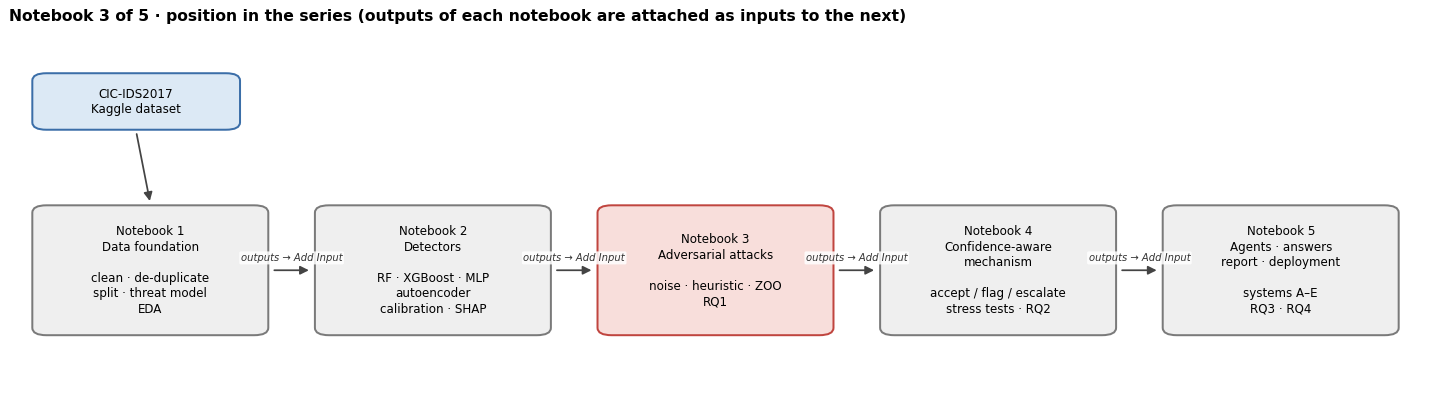

In [ ]:
import os, sys
from pathlib import Path
sys.path.insert(0, str(Path(os.environ.get("IDS_WORK_ROOT", "/kaggle/working")) / "presentation"))
import matplotlib.pyplot as plt
from present_lib import flowchart

# Where this notebook sits in the five-notebook series (highlighted box = this notebook)
nodes = {
    "data": (9, 40, 14, 7, "CIC-IDS2017\nKaggle dataset", "data"),
    "n1": (10, 17, 16, 17, 'Notebook 1\nData foundation\n\nclean · de-duplicate\nsplit · threat model\nEDA', "out"),
    "n2": (30, 17, 16, 17, 'Notebook 2\nDetectors\n\nRF · XGBoost · MLP\nautoencoder\ncalibration · SHAP', "out"),
    "n3": (50, 17, 16, 17, 'Notebook 3\nAdversarial attacks\n\nnoise · heuristic · ZOO\nRQ1', "attack"),
    "n4": (70, 17, 16, 17, 'Notebook 4\nConfidence-aware\nmechanism\n\naccept / flag / escalate\nstress tests · RQ2', "out"),
    "n5": (90, 17, 16, 17, 'Notebook 5\nAgents · answers\nreport · deployment\n\nsystems A–E\nRQ3 · RQ4', "out"),
}
edges = [("data", "n1")] + [(f"n{i}", f"n{i+1}", "outputs → Add Input") for i in range(1, 5)]
flowchart(nodes, edges, size=(16, 4.6), title="Notebook 3 of 5 · position in the series (outputs of each notebook are attached as inputs to the next)")
plt.show()

## 1 · What this notebook does

This notebook answers **RQ1**: *How does controlled adversarial perturbation affect the detection performance and explanation stability of the selected models?* It attacks the three classifiers with three attacks that all respect the threat model of Notebook 1, measures the fall in macro-F1 and the change in SHAP explanations, and tests whether the change is caused by the attack or by any change.

| Item | Detail |
|---|---|
| Role in the project | **RQ1 / objective O1** |
| Input | Outputs of Notebooks 1 and 2 |
| Output folder | `/kaggle/working/nb3_attacks/` (adversarial flows in real units for test-lite and thr-lite, SHAP on attacked flows, stability tables, figures) |
| Run time | the longest of Notebooks 1–4: estimated 1.5–2 hours (measured: SHAP on attacked flows alone took 68 minutes) |
| Hardware | **GPU T4** · Internet not needed |
| Report sections | 4.6, 4.7, 5.2 · Table 8 · Figure 8 |

## 2 · How to run

**General Kaggle steps (same for every notebook)**
1. On Kaggle, click **Create → New Notebook**, then **File → Import Notebook** and upload this `.ipynb` file.
2. In the right-hand panel, open **Session options** and set the **Accelerator** and **Internet** as listed below.
3. Click **+ Add Input** and attach the inputs listed below. Outputs of your earlier notebooks are found under **Your Work → Notebooks**: choose the notebook and attach its latest **output** version.
4. Click **Save Version → Save & Run All (Commit)**. Running as a saved version keeps the files in `/kaggle/working/` as this notebook's **output**, which the next notebook attaches.
5. When the run finishes, open the version and check the **Final checks** section (every row should show ✔).

**Why this works.** Every Part starts from a clean memory state and finds what it needs by file name, first in `/kaggle/working/` and then anywhere under `/kaggle/input/`. Attached outputs are therefore found automatically; no paths need to be edited.

**For the viva you do not need to re-run anything.** This file already contains every output of the reported run, so all tables and figures can be shown immediately.

**Settings for this notebook**

| Setting | Value |
|---|---|
| Accelerator | GPU T4 ×2 (or ×1) |
| Internet | Off |
| Inputs to attach | Outputs of **Notebook 1** and **Notebook 2** |

**Settings you can change** (Section 3.1)

| Constant | Reported value | Meaning |
|---|---|---|
| `EPSILONS` | 0.05, 0.1, 0.2, 0.5, 1.0 | attack budgets (relative to each feature's scale) |
| `ATTACKS` | noise, heuristic, zoo | the three attacks (transfer is evaluated from the ZOO flows) |
| `ZOO_STEPS` | 10 | optimisation steps per flow (141 model queries) |
| `ZOO_H_FRAC`, `ZOO_LR_FRAC` | 0.25, 0.25 | finite-difference and step sizes as fractions of ε |
| `SHAP_ATTACKS` | noise, zoo | SHAP recomputed for the control and the adaptive attack |

## 3 · Key concepts and techniques

| Concept | In plain words | Why it is used here | Section |
|---|---|---|---|
| Evasion attack | Change an attack flow so the model calls it Benign | The attacker's goal | 3.1 |
| Budget ε | Each feature may move by at most ε × its typical size | Controls attack strength (0.05 to 1.0) | 3.1 |
| Threat-model projection | Every proposed change is turned into a flow the attacker could really send | Realistic attacks only (13 controllable features) | 3.3 |
| Random noise (control) | Random realistic change of the same size | Separates "any change" from "targeted change" | 3.3 |
| Heuristic attack | Padding, delays and dummy packets at full budget | Simple attacker | 3.3 |
| ZOO (zeroth-order optimisation) | Black-box attack: estimate by finite differences how each feature changes P(Benign), then step to raise it | Needs only query access; works on tree models; stays inside the projection | 3.3–3.4 |
| Transferability | Do flows crafted against one model fool the others? | Realistic attacker who does not know the exact model | 3.7 |
| Kendall τ, top-k Jaccard, RBO, group τ | Agreement between clean and attacked SHAP rankings (1 = identical) | Measure explanation stability | 3.8 |
| Wilcoxon signed-rank test | Paired test on the same flows: ZOO vs noise | Is the instability caused by the attack? | 3.8b |
| Feature freezing | Repeat the attack with the TCP-window feature fixed | Is the vulnerability one shortcut or spread out? | 3.9b |

## 4 · Methodology at a glance

| Step | What happens | Why | Section |
|---|---|---|---|
| Load | Models, calibrators, threat model, test-lite and thr-lite flows | Same flows for every model | 3.2 |
| Attack engine | Noise, heuristic and ZOO, all through the projection | Realistic attacks | 3.3 |
| Generate | Attacks at 5 budgets against each classifier | 50 configurations | 3.4 |
| Compliance | Check every adversarial flow against the threat model | 0 hard violations | 3.5 |
| Detection | Macro-F1 and evasion rate of every model on every attacked set | RQ1 (detection) | 3.6 |
| Transfer | Score every ZOO flow with all models | Attacker without model knowledge | 3.7 |
| Explanations | SHAP on attacked flows; τ, Jaccard, RBO vs clean | RQ1 (explanations) | 3.8 |
| Attack vs any change | Paired Wilcoxon test ZOO vs noise | Causality of instability | 3.8b |
| Sensitivity | Freeze `Init_Win_bytes_forward` and re-attack | Is there a single shortcut? | 3.9b |

## 5 · Key results to remember

| Result | XGBoost | Random Forest | MLP |
|---|---|---|---|
| Clean macro-F1 (test-lite) | 0.950 | 0.922 | 0.918 |
| Macro-F1 at ε = 0.05 (ZOO) | 0.656 | 0.443 | 0.725 |
| Macro-F1 at ε = 1.0 (ZOO) | **0.253** | **0.207** | **0.194** |
| Evasion rate at ε = 1.0 | 79.4 % | 83.9 % | 87.0 % |
| SHAP Kendall τ at ε = 1.0 | 0.549 | 0.586 | 0.472 |

- **0** hard threat-model violations in all 50 configurations.
- ZOO less stable than noise of the same size in **15 of 15** model/budget cases (Wilcoxon).
- **48.1 %** of flows whose prediction did *not* change still had their explanation substantially changed (τ < 0.8).
- Transfer: mean evasion 0.835 against the model attacked, **0.669** against the other models.
- Random noise of the same size already causes most of the drop for the tree models; freezing the TCP-window feature removes only part of it.

---
# Original project code and outputs
Everything below is the project code exactly as in the reported run, with its outputs. Grey **Findings** boxes are generated by the code above them.

<a id="part3"></a>
# Part 3 · Adversarial Attacks: Detection Performance and Explanation Stability (RQ1)

| | |
|---|---|
| **Goal** | Attack the detectors within the threat model and measure the drop in macro-F1 and the change in SHAP explanations. |
| **Answers** | **RQ1 / O1** |
| **Inputs** | Parts 1–2 outputs |
| **Outputs used later** | adversarial flows, predictions under attack, SHAP stability, TCP-window ablation |
| **Run time** | ≈ 2.5 h (GPU) |

#### Research question answered here
> **RQ1:** How does controlled adversarial perturbation affect the detection performance and explanation stability of the selected intrusion-detection models?
>
> **O1:** Develop a threat model based on the attacker-controllable feature space, and examine the decline in macro-F1 and the stability of SHAP rankings of the chosen classifiers following the attack.

The threat model was built and validated in Part 1; this part applies it.

#### Design
| Element | Choice | Why |
|---|---|---|
| Attacker goal | **evasion**: make an attack flow look *Benign* | the realistic goal of an intrusion attacker |
| Attacker capability | only the 13 controllable client-side features, through `project_to_threat_model` | every adversarial flow is realisable (Section 1.15) |
| Budget ε | each controllable feature may move by at most ε × its scale (its own value, or the typical training value if it is 0) | "controlled" perturbation: results are reported as curves over ε |
| Attacks | **noise** (random, control) · **heuristic** (padding, delays, dummy packets at full budget; model-agnostic) · **ZOO** (zeroth-order optimisation: query-only, estimated gradients through the full constrained pipeline; adaptive to each model) · **transfer** (ZOO flows crafted on one model, tested on the others) | a control, a naive attacker, a strong adaptive attacker, and a realistic black-box setting |
| Flows | attack flows of `test-lite` (results) and `thr-lite` (saved for tuning in Part 4); benign flows are never perturbed | the attacker controls only their own traffic |
| Explanation stability | SHAP of the attacked flow vs SHAP of the same clean flow: Kendall τ, top-k Jaccard, rank-biased overlap (RBO), feature-group τ, cosine similarity | O1's "stability of SHAP rankings", at feature and group level |
| Controls | stability under ZOO vs under random noise of the same budget (Wilcoxon signed-rank); flipped vs unflipped predictions | separates *attack-specific* instability from ordinary sensitivity to change |

Why not plain gradient attacks (FGSM/PGD) on the model input? They change model inputs freely, ignoring that most features are fixed or derived from others, so the resulting "flows" could not exist. ZOO estimates gradients **through** the threat-model projection, so every step stays realistic, and it applies equally to tree models and the MLP.

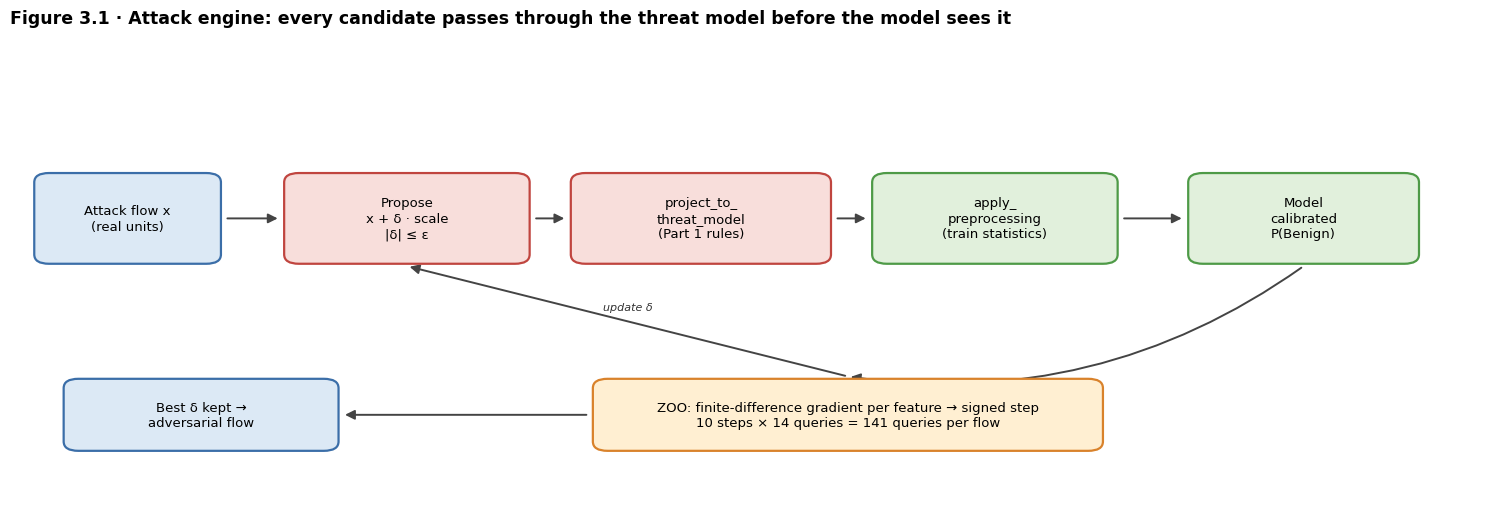

In [58]:
import os, sys
from pathlib import Path
sys.path.insert(0, str(Path(os.environ.get("IDS_WORK_ROOT", "/kaggle/working")) / "presentation"))
import matplotlib.pyplot as plt
from present_lib import flowchart

nodes = {
    "x": (8, 30, 12, 9, "Attack flow x\n(real units)", "data"),
    "prop": (27, 30, 16, 9, "Propose\nx + δ · scale\n|δ| ≤ ε", "attack"),
    "proj": (47, 30, 17, 9, "project_to_\nthreat_model\n(Part 1 rules)", "attack"),
    "pre": (67, 30, 16, 9, "apply_\npreprocessing\n(train statistics)", "model"),
    "mod": (88, 30, 15, 9, "Model\ncalibrated\nP(Benign)", "model"),
    "zoo": (57, 9, 34, 7, "ZOO: finite-difference gradient per feature → signed step\n10 steps × 14 queries = 141 queries per flow", "policy"),
    "out": (13, 9, 18, 7, "Best δ kept →\nadversarial flow", "data"),
}
edges = [("x", "prop"), ("prop", "proj"), ("proj", "pre"), ("pre", "mod"), ("mod", "zoo", "", -0.2),
         ("zoo", "prop", "update δ", 0.0), ("zoo", "out")]
flowchart(nodes, edges, size=(15, 5.2), title="Figure 3.1 · Attack engine: every candidate passes through the threat model before the model sees it")
plt.show()

## 3.1 · Setup and decisions

In [59]:
# Fresh start: this Part reloads everything it needs from the files saved by earlier Parts,
# so memory from the previous Part (e.g. the 2.8 M-row table of Part 1) is released first.
%reset -f
import gc; gc.collect()

0

In [60]:
import os, sys, json, time, platform, warnings, importlib, gc, itertools
from pathlib import Path
from datetime import datetime, timezone
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import joblib, xgboost as xgb, shap
from scipy.stats import kendalltau, wilcoxon, mannwhitneyu
from IPython.display import display, Markdown
warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 220)

INPUT_ROOT = Path(os.environ.get("IDS_INPUT_ROOT", "/kaggle/input"))
WORK_ROOT  = Path(os.environ.get("IDS_WORK_ROOT", "/kaggle/working"))
OUT_DIR = WORK_ROOT / "nb3_attacks"; FIG_DIR = OUT_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
NOTEBOOK_ID = "nb3_attacks_v1"
SEED = 42; rng = np.random.default_rng(SEED)

# ---------------- Decisions ----------------
EPSILONS      = [0.05, 0.1, 0.2, 0.5, 1.0]     # attack budgets (relative to each feature's scale)
ATTACKS       = ["noise", "heuristic", "zoo"]   # transfer is evaluated automatically from the ZOO flows
TARGET_CLASS  = "Benign"                        # evasion: push attack flows towards Benign
ZOO_STEPS     = 10                              # optimisation steps per flow
ZOO_H_FRAC    = 0.25                            # finite-difference step = ZOO_H_FRAC × ε
ZOO_LR_FRAC   = 0.25                            # step size = ZOO_LR_FRAC × ε per iteration
ATTACK_SETS   = ["test_lite", "thr_lite"]       # thr-lite flows are saved for Part 4
SHAP_EPS      = EPSILONS                        # budgets at which SHAP is recomputed (test-lite)
SHAP_ATTACKS  = ["noise", "zoo"]                # zoo = adaptive attack on that model; noise = control
TOP_K         = (5, 10)
RBO_P, RBO_DEPTH = 0.9, 20
N_BOOT        = 200

def findings(rows, meaning=""):
    text = "> #### Findings\n> | Check | Result |\n> |---|---|\n" + "".join(f"> | {a} | {b} |\n" for a, b in rows)
    if meaning: text += f">\n> **Meaning:** {meaning}\n"
    display(Markdown(text))

def savefig(name):
    plt.tight_layout(); plt.savefig(FIG_DIR / name, dpi=200, bbox_inches="tight"); plt.show()

def to_builtin(o):
    if isinstance(o, np.integer): return int(o)
    if isinstance(o, np.floating): return float(o) if np.isfinite(o) else None
    if isinstance(o, np.bool_): return bool(o)
    if isinstance(o, np.ndarray): return o.tolist()
    if isinstance(o, (Path, tuple)): return str(o) if isinstance(o, Path) else list(o)
    raise TypeError(type(o))

## 3.2 · Load data, threat model and detectors

In [61]:
def find_dir(marker, local):
    hits = sorted((WORK_ROOT / local).glob(marker)) + sorted(INPUT_ROOT.rglob(marker))  # this run first, then attached outputs
    assert hits, f"{marker} not found: attach the output of the earlier part with 'Add Input'."
    return hits[0].parent
NB2 = find_dir("detectors_config.json", "nb2_detectors")
NB1 = find_dir("threat_model.json", "nb1_data_foundation")
sys.path.insert(0, str(NB1)); sys.path.insert(0, str(NB2))
import preprocess_lib as pl, models_lib as ml
CFG = json.load(open(NB2 / "detectors_config.json")); fs = json.load(open(NB1 / "feature_sets.json"))
SPEC = json.load(open(NB1 / "threat_model.json")); PARAMS = json.load(open(NB1 / "preprocessing_params.json"))
FEATURE_GROUPS = json.load(open(NB1 / "feature_groups.json"))
CLASSES, COLS = CFG["classes"], CFG["model_cols"]; K = len(CLASSES)
CLASSIFIERS, DETECTORS = CFG["classifiers"], CFG["anomaly_detectors"]
TARGET_ID, BENIGN_ID = CLASSES.index(TARGET_CLASS), CLASSES.index("Benign")
ALPHA = CFG["anomaly_alpha"]
NEEDS_TORCH = "mlp" in CLASSIFIERS or "autoencoder" in DETECTORS
if NEEDS_TORCH:
    import torch
DEVICE = "cuda" if NEEDS_TORCH and torch.cuda.is_available() else "cpu"

# Models, calibrators, anomaly detectors
MD = NB2 / "models"; MODELS, CALIB, ANOM = {}, {}, {}
for name in CLASSIFIERS:
    if name == "rf": MODELS[name] = joblib.load(MD / "rf.joblib")
    elif name == "xgb":
        MODELS[name] = xgb.XGBClassifier(); MODELS[name].load_model(MD / "xgb.json")
        try: MODELS[name].set_params(device=DEVICE)
        except Exception: pass
    elif name == "mlp":
        ck = torch.load(MD / "mlp.pt", map_location=DEVICE)
        MODELS[name] = ml.MLP(ck["d_in"], ck["n_out"], tuple(ck["hidden"]), ck["dropout"]); MODELS[name].load_state_dict(ck["state_dict"])
        MODELS[name].to(DEVICE).eval()
    CALIB[name] = joblib.load(MD / f"calibrator_{name}.joblib")
for name in DETECTORS:
    if name == "iforest": ANOM[name] = joblib.load(MD / "iforest.joblib")
    else:
        ck = torch.load(MD / "autoencoder.pt", map_location=DEVICE)
        ANOM[name] = ml.AE(ck["d_in"]); ANOM[name].load_state_dict(ck["state_dict"]); ANOM[name].to(DEVICE).eval()
AREF = np.load(NB2 / "anomaly_reference.npz")

def raw_logits(name, X):
    if name == "mlp": return ml.torch_logits(MODELS["mlp"], X, DEVICE)
    return np.log(np.clip(MODELS[name].predict_proba(X), 1e-12, 1))
def proba(name, X):
    P = CALIB[name].predict_proba(raw_logits(name, X)); return P / P.sum(1, keepdims=True)
def anomaly_pvalue(name, X):
    s = -ANOM[name].score_samples(X) if name == "iforest" else ml.ae_score(ANOM[name], X, DEVICE)
    return ml.conformal_pvalues(AREF[f"{name}_cal_benign_scores"], s)

# Clean flows in real units
FEATS = list(dict.fromkeys(fs["features_raw"] + fs["features_engineered"]))
meta = ["Label", "label_family", "label_id", "split", "in_train_sample", "in_test_lite", "in_thr_lite", "in_agent_eval"]
clean = pd.read_parquet(NB1 / "cicids2017_clean.parquet", columns=FEATS + meta)
for c in ["Label", "label_family", "split"]: clean[c] = clean[c].astype(str)
SETS = {s: np.flatnonzero(clean[f"in_{s}"].to_numpy()) for s in ATTACK_SETS}
CTRL = [c for c, s in SPEC["features"].items() if s["role"] == "controllable" and c in clean.columns]
INC = np.array([SPEC["features"][c]["direction"] == "increase" for c in CTRL])

# Consistency: the saved transformation reproduces Part 1's model inputs exactly
mr_cols = pd.read_parquet(NB1 / "cicids2017_model_ready.parquet", columns=COLS)
chk_rows = SETS["test_lite"][:500]
consistent = np.allclose(pl.apply_preprocessing(clean.iloc[chk_rows][FEATS], PARAMS)[COLS].to_numpy("float32"),
                         mr_cols.iloc[chk_rows].to_numpy("float32"), atol=1e-4)
del mr_cols

# Per-feature scale: a flow's own value, or the typical non-zero training value when the flow's value is 0
tr = clean.loc[clean["in_train_sample"], CTRL]
TYPICAL = np.array([np.nanmedian(np.abs(tr[c][tr[c] != 0])) if (tr[c] != 0).any() else 1.0 for c in CTRL])
TYPICAL = np.where(np.isfinite(TYPICAL) & (TYPICAL > 0), TYPICAL, 1.0); del tr
display(pd.DataFrame({"direction": [SPEC["features"][c]["direction"] for c in CTRL], "typical_scale": TYPICAL.round(2),
                      "in_model": [c in COLS for c in CTRL]}, index=CTRL).rename_axis("controllable feature"))
findings([("Classifiers / anomaly detectors", f"{', '.join(CLASSIFIERS)} / {', '.join(DETECTORS)}"),
          ("Attack sets", ", ".join(f"{k}: {len(v):,} flows ({int((clean['label_id'].to_numpy()[v] != BENIGN_ID).sum()):,} attack)" for k, v in SETS.items())),
          ("Controllable features", f"{len(CTRL)} ({int(INC.sum())} increase-only)"),
          ("Transformation reproduces Part 1 inputs", "yes ✔" if consistent else "✘ NO"),
          ("Device", DEVICE)])
assert consistent

,direction,typical_scale,in_model
controllable feature,,,
Flow Duration,increase,392528.50,True
Total Fwd Packets,increase,3.00,True
Total Length of Fwd Packets,increase,82.00,True
Fwd Packet Length Max,increase,46.00,True
Fwd Packet Length Min,any,36.00,True
Fwd Packet Length Std,any,116.95,True
Fwd IAT Total,increase,855961.00,True
Fwd IAT Std,any,2984589.35,True
Fwd IAT Max,increase,500030.00,False


> #### Findings
> | Check | Result |
> |---|---|
> | Classifiers / anomaly detectors | rf, xgb, mlp / iforest, autoencoder |
> | Attack sets | test_lite: 2,083 flows (1,783 attack), thr_lite: 1,740 flows (1,440 attack) |
> | Controllable features | 13 (8 increase-only) |
> | Transformation reproduces Part 1 inputs | yes ✔ |
> | Device | cuda |


## 3.3 · Attack engine
A perturbation is a matrix δ (flows × controllable features) in units of ε × scale. Every candidate goes through the same path:

**propose** `x + δ·scale` → **`project_to_threat_model`** (directions, bounds, integers, dependent features, ordering rules) → **`apply_preprocessing`** (Part 1's training statistics) → **model**.

**ZOO** (Chen et al., 2017) estimates, for each controllable feature, how the model's calibrated *P(Benign)* changes when that feature is nudged (finite difference), then takes a signed step in the direction that raises *P(Benign)*, staying inside the ε-box. Where the model is flat (common for trees), a random direction is tried instead, so the search does not stall. The best perturbation found per flow is kept. Queries per flow = steps × (controllable features + 1).

In [62]:
def scale_of(base):
    v = np.abs(base[CTRL].to_numpy("float64"))
    return np.where(v > 0, v, TYPICAL)

def realise(base, delta, scale):
    prop = base.copy()
    prop[CTRL] = base[CTRL].to_numpy("float64") + delta * scale
    adv, changed = pl.project_to_threat_model(base, prop, SPEC)
    return adv

def model_input(adv):
    return pl.apply_preprocessing(adv, PARAMS)[COLS].to_numpy("float32")

def bounds(eps):
    return np.where(INC, 0.0, -eps), np.full(len(CTRL), eps)

def attack_noise(base, scale, eps, r):
    lo, hi = bounds(eps); return r.uniform(lo, hi, size=(len(base), len(CTRL)))

def attack_heuristic(base, scale, eps, r):
    return np.tile(np.where(INC, eps, 0.0), (len(base), 1))            # pad, delay and add packets to the full budget

QUERIES = {}
def attack_zoo(base, scale, eps, r, target_model):
    lo, hi = bounds(eps); h, lr = ZOO_H_FRAC * eps, ZOO_LR_FRAC * eps
    score = lambda d: proba(target_model, model_input(realise(base, d, scale)))[:, TARGET_ID]
    delta = np.zeros((len(base), len(CTRL))); cur = score(delta)
    best_d, best_s = delta.copy(), cur.copy(); q = 1
    for _ in range(ZOO_STEPS):
        g = np.zeros_like(delta)
        for j in range(len(CTRL)):
            d2 = delta.copy(); up = np.clip(d2[:, j] + h, lo[j], hi[j]); down = np.clip(d2[:, j] - h, lo[j], hi[j])
            use_up = up != d2[:, j]; d2[:, j] = np.where(use_up, up, down)
            diff = score(d2) - cur; q += 1
            g[:, j] = np.where(use_up, diff, -diff)
        flat = g == 0
        g[flat] = r.choice([-1.0, 1.0], size=int(flat.sum()))          # explore where the model is flat
        delta = np.clip(delta + lr * np.sign(g), lo, hi); cur = score(delta); q += 1
        better = cur > best_s; best_d[better], best_s[better] = delta[better], cur[better]
    QUERIES[target_model] = q
    return best_d

# Quick self-test on a few flows: zero perturbation reproduces the clean flow exactly
b0 = clean.iloc[SETS["test_lite"][:50]][FEATS]
assert np.allclose(model_input(realise(b0, np.zeros((50, len(CTRL))), scale_of(b0))), model_input(b0))
print("attack engine ready: zero perturbation leaves flows unchanged ✔")

attack engine ready: zero perturbation leaves flows unchanged ✔


## 3.4 · Generate adversarial flows
For every set (`test-lite`, `thr-lite`), budget ε and attack: noise and heuristic once (model-agnostic); ZOO once **per target model**. Only attack flows are perturbed. Every adversarial flow is then scored by **all** classifiers and anomaly detectors, so the transfer results come for free (ZOO crafted on model A, evaluated on model B).

In [63]:
t_all = time.time(); ADV, TIMES = {}, []
for set_name, rows in SETS.items():
    att_rows = rows[clean["label_id"].to_numpy()[rows] != BENIGN_ID]
    base = clean.iloc[att_rows][FEATS].reset_index(drop=True); scale = scale_of(base)
    for eps in EPSILONS:
        for attack in ATTACKS:
            targets = CLASSIFIERS if attack == "zoo" else ["none"]
            for tgt in targets:
                t = time.time(); r = np.random.default_rng(SEED + int(eps * 1000))
                if attack == "noise":       d = attack_noise(base, scale, eps, r)
                elif attack == "heuristic": d = attack_heuristic(base, scale, eps, r)
                else:                       d = attack_zoo(base, scale, eps, r, tgt)
                adv = realise(base, d, scale); adv.index = att_rows
                ADV[(set_name, attack, tgt, eps)] = adv
                TIMES.append({"set": set_name, "attack": attack, "target": tgt, "eps": eps, "flows": len(adv),
                              "seconds": round(time.time() - t, 1), "ms_per_flow": round(1e3 * (time.time() - t) / max(len(adv), 1), 2),
                              "queries_per_flow": QUERIES.get(tgt, 0) if attack == "zoo" else 0})
        print(f"{set_name} ε={eps}: done ({time.time() - t_all:.0f} s total)")
TIMES = pd.DataFrame(TIMES)
display(TIMES[TIMES.set == "test_lite"].pivot_table(index=["attack", "target"], columns="eps", values="ms_per_flow"))
findings([("Adversarial configurations generated", f"{len(ADV)}"),
          ("ZOO queries per flow", f"{int(TIMES.loc[TIMES.attack == 'zoo', 'queries_per_flow'].max())}"),
          ("Total generation time", f"{time.time() - t_all:.0f} s")],
         "attack cost (time and queries per flow) is recorded for the trade-off analysis in RQ4.")

test_lite ε=0.05: done (25 s total)
test_lite ε=0.1: done (49 s total)
test_lite ε=0.2: done (73 s total)
test_lite ε=0.5: done (99 s total)
test_lite ε=1.0: done (124 s total)
thr_lite ε=0.05: done (148 s total)
thr_lite ε=0.1: done (172 s total)
thr_lite ε=0.2: done (196 s total)
thr_lite ε=0.5: done (220 s total)
thr_lite ε=1.0: done (243 s total)


eps               0.05  0.10  0.20  0.50  1.00
attack    target                              
heuristic none    0.01  0.01  0.01  0.01  0.01
noise     none    0.01  0.01  0.01  0.01  0.01
zoo       mlp     2.05  2.05  2.04  2.12  2.06
          rf      8.12  8.15  8.09  8.55  8.17
          xgb     3.62  3.48  3.54  3.74  3.62

> #### Findings
> | Check | Result |
> |---|---|
> | Adversarial configurations generated | 50 |
> | ZOO queries per flow | 141 |
> | Total generation time | 243 s |
>
> **Meaning:** attack cost (time and queries per flow) is recorded for the trade-off analysis in RQ4.


## 3.5 · Threat-model compliance of every adversarial flow
Before any result is reported, every generated flow is checked against the threat model: uncontrollable features unchanged, increase-only features not decreased, integer features integer, values within bounds, and the share of flows whose controllable changes stayed within the budget ε (projection rules such as *min ≤ mean* may move a value slightly past it).

In [64]:
COMP = []
for key, adv in ADV.items():
    base = clean.loc[adv.index, FEATS]; v = {}
    unc = [c for c, s in SPEC["features"].items() if s["role"] == "uncontrollable" and c in adv.columns]
    v["uncontrollable_changed"] = int((~np.isclose(adv[unc].to_numpy("float64"), base[unc].to_numpy("float64"), equal_nan=True)).any(1).sum())
    o, n = base[CTRL].to_numpy("float64"), adv[CTRL].to_numpy("float64")
    v["increase_violated"] = int((n[:, INC] < o[:, INC] - 1e-9).any(1).sum())
    ints = np.array([SPEC["features"][c]["integer"] for c in CTRL])
    v["non_integer"] = int(((np.abs(n[:, ints] - np.round(n[:, ints])) > 1e-6) & (n[:, ints] != o[:, ints])).any(1).sum())
    hi = np.array([max(SPEC["features"][c]["high"], 0) for c in CTRL])
    v["above_bound"] = int(((n > hi + 1e-6) & (n > o)).any(1).sum())
    within = (np.abs(n - o) <= key[3] * scale_of(base) * (1 + 1e-6) + 1.0).all(1)
    COMP.append({"set": key[0], "attack": key[1], "target": key[2], "eps": key[3], **v,
                 "within_budget_%": round(100 * within.mean(), 2), "flows_changed_%": round(100 * (np.abs(n - o) > 0).any(1).mean(), 1)})
COMP = pd.DataFrame(COMP)
hard = COMP[["uncontrollable_changed", "increase_violated", "non_integer", "above_bound"]].sum()
display(hard.to_frame("violating flows (all configurations)"))
display(COMP[COMP.set == "test_lite"].groupby(["attack", "eps"])[["within_budget_%", "flows_changed_%"]].mean().round(2))
findings([("Hard threat-model violations", "0 ✔" if hard.sum() == 0 else f"{int(hard.sum())} ✘"),
          ("Flows within budget (minimum over configurations)", f"{COMP['within_budget_%'].min():.1f}%")],
         "every adversarial flow is realisable by the attacker defined in Part 1.")
assert hard.sum() == 0

,violating flows (all configurations)
uncontrollable_changed,0
increase_violated,0
non_integer,0
above_bound,0


within_budget_%  flows_changed_%
attack    eps                                   
heuristic 0.05            81.60           100.00
          0.10            81.88           100.00
          0.20            89.23           100.00
          0.50           100.00           100.00
          1.00           100.00           100.00
noise     0.05            81.60           100.00
          0.10            81.72           100.00
          0.20            82.61           100.00
          0.50           100.00           100.00
          1.00           100.00           100.00
zoo       0.05            89.18            95.77
          0.10            90.93            96.03
          0.20            92.37            97.87
          0.50           100.00            99.97
          1.00           100.00           100.00

> #### Findings
> | Check | Result |
> |---|---|
> | Hard threat-model violations | 0 ✔ |
> | Flows within budget (minimum over configurations) | 81.6% |
>
> **Meaning:** every adversarial flow is realisable by the attacker defined in Part 1.


## 3.6 · Detection performance under attack
For each configuration the set is evaluated as the deployed system would see it: **benign flows unchanged, attack flows replaced by their adversarial version**. Metrics: macro-F1 (with bootstrap 95% CI), evasion rate (attack flows classified Benign), attack-detection rate (attack flows classified as any attack), and the anomaly detectors' detection rate (p < α).

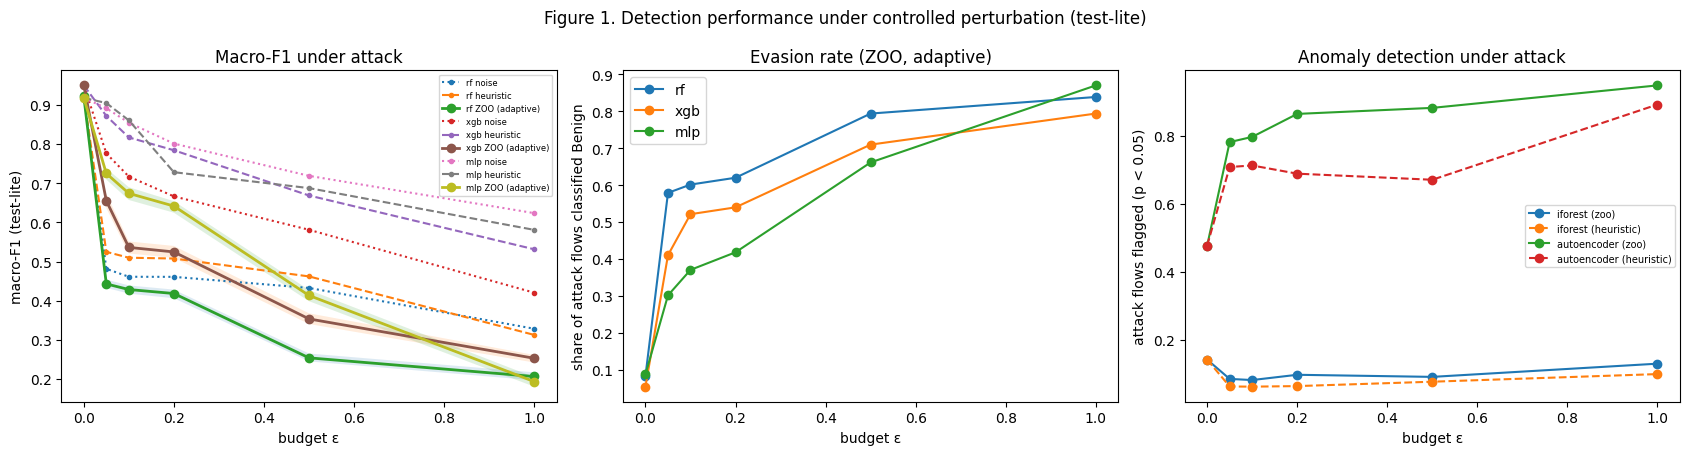

eps,clean,0.05,0.1,0.2,0.5,1.0
macro-F1 under adaptive ZOO,,,,,,
rf,0.9223,0.4431,0.4287,0.4185,0.2542,0.2066
xgb,0.9501,0.6555,0.5363,0.5248,0.3537,0.2532
mlp,0.9184,0.7252,0.6743,0.6419,0.4136,0.1936


eps,0.05,0.1,0.2,0.5,1.0
macro-F1 drop,,,,,
rf,0.4793,0.4936,0.5038,0.6681,0.7157
xgb,0.2946,0.4138,0.4253,0.5964,0.6969
mlp,0.1932,0.2440,0.2765,0.5048,0.7247


,rf,xgb,mlp
evasion rate at ε = 1.0,,,
Bot,1.000,0.986,1.000
BruteForce,1.000,1.000,0.977
DDoS,0.843,0.643,0.427
DoS,0.200,0.147,0.847
PortScan,1.000,1.000,0.987
WebAttack,1.000,1.000,0.993


> #### Findings
> | Check | Result |
> |---|---|
> | rf: clean → ε = 1.0 | 0.9223 → 0.2066 (−0.7157) |
> | xgb: clean → ε = 1.0 | 0.9501 → 0.2532 (−0.6969) |
> | mlp: clean → ε = 1.0 | 0.9184 → 0.1936 (−0.7247) |
> | Most / least robust model (drop at max ε) | xgb / mlp |
> | Drop under random noise at ε = 1.0 (control) | rf −0.5937, xgb −0.5294, mlp −0.2945 |
> | Most evasive family at max ε | rf: Bot, xgb: BruteForce, mlp: Bot |
>
> **Meaning:** the adaptive ZOO attack is the relevant worst case and noise is the control: the gap between the two shows how much of the decline is due to targeted manipulation rather than any change. The per-family table shows which attack types are easiest to disguise.


In [65]:
def macro_f1(y, p):
    cm = np.bincount(y * K + p, minlength=K * K).reshape(K, K)
    tp = np.diag(cm); prec = tp / np.maximum(cm.sum(0), 1); rec = tp / np.maximum(cm.sum(1), 1)
    f1 = np.where(prec + rec > 0, 2 * prec * rec / np.maximum(prec + rec, 1e-12), 0)
    return float(f1[cm.sum(1) > 0].mean())
def boot_ci(y, p, n=N_BOOT):
    r = np.random.default_rng(SEED); v = [macro_f1(y[b], p[b]) for b in (r.integers(0, len(y), len(y)) for _ in range(n))]
    return np.percentile(v, [2.5, 97.5])

def set_inputs(set_name, adv=None):
    rows = SETS[set_name]; X = model_input(clean.iloc[rows][FEATS])
    if adv is not None:
        pos = pd.Series(np.arange(len(rows)), index=rows).loc[adv.index].to_numpy(); X[pos] = model_input(adv)
    return rows, X

PRED_STORE, RES = [], []
configs = [(s, "clean", "none", 0.0) for s in SETS] + list(ADV.keys())
for key in configs:
    s, attack, tgt, eps = key
    rows, X = set_inputs(s, ADV.get(key)); y = clean["label_id"].to_numpy()[rows]; att = y != BENIGN_ID
    rec = {"set": s, "attack": attack, "target": tgt, "eps": eps, "row_id": rows, "label_id": y}
    for m in CLASSIFIERS:
        P = proba(m, X); p = P.argmax(1); rec[f"{m}_P"] = P.astype("float32")
        lo, hi = boot_ci(y, p) if s == "test_lite" else (np.nan, np.nan)
        RES.append({"set": s, "attack": attack, "target": tgt, "eps": eps, "evaluated_on": m, "macro_F1": macro_f1(y, p),
                    "CI_low": lo, "CI_high": hi, "evasion_rate": float((p[att] == BENIGN_ID).mean()),
                    "attack_detection_rate": float((p[att] != BENIGN_ID).mean()), "family_accuracy_attacks": float((p[att] == y[att]).mean())})
    for a in DETECTORS:
        pv = anomaly_pvalue(a, X); rec[f"{a}_pvalue"] = pv.astype("float32")
        RES.append({"set": s, "attack": attack, "target": tgt, "eps": eps, "evaluated_on": a,
                    "attack_detection_rate": float((pv[att] < ALPHA).mean()), "benign_false_alarm": float((pv[~att] < ALPHA).mean())})
    PRED_STORE.append(rec)
RES = pd.DataFrame(RES)

T = RES[(RES.set == "test_lite") & RES.evaluated_on.isin(CLASSIFIERS)]
clean_f1 = T[T.attack == "clean"].set_index("evaluated_on")["macro_F1"]
own = T[(T.attack == "zoo") & (T.target == T.evaluated_on)]
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
for m in CLASSIFIERS:
    for attack, st in [("noise", ":"), ("heuristic", "--")]:
        d = T[(T.attack == attack) & (T.evaluated_on == m)].sort_values("eps")
        axes[0].plot([0] + d.eps.tolist(), [clean_f1[m]] + d.macro_F1.tolist(), st, marker=".", label=f"{m} {attack}")
    d = own[own.evaluated_on == m].sort_values("eps")
    axes[0].plot([0] + d.eps.tolist(), [clean_f1[m]] + d.macro_F1.tolist(), "-", marker="o", lw=2, label=f"{m} ZOO (adaptive)")
    axes[0].fill_between(d.eps, d.CI_low, d.CI_high, alpha=0.15)
    axes[1].plot([0] + d.eps.tolist(), [T[(T.attack == "clean") & (T.evaluated_on == m)].evasion_rate.iloc[0]] + d.evasion_rate.tolist(),
                 marker="o", label=m)
axes[0].set_xlabel("budget ε"); axes[0].set_ylabel("macro-F1 (test-lite)"); axes[0].set_title("Macro-F1 under attack"); axes[0].legend(fontsize=6)
axes[1].set_xlabel("budget ε"); axes[1].set_ylabel("share of attack flows classified Benign"); axes[1].set_title("Evasion rate (ZOO, adaptive)"); axes[1].legend()
A = RES[(RES.set == "test_lite") & RES.evaluated_on.isin(DETECTORS)]
for a in DETECTORS:
    for attack, st in [("zoo", "-"), ("heuristic", "--")]:
        d = A[(A.attack == attack) & (A.evaluated_on == a)].groupby("eps")["attack_detection_rate"].mean()
        c0 = A[(A.attack == "clean") & (A.evaluated_on == a)].attack_detection_rate.iloc[0]
        axes[2].plot([0] + d.index.tolist(), [c0] + d.tolist(), st, marker="o", label=f"{a} ({attack})")
axes[2].set_xlabel("budget ε"); axes[2].set_ylabel(f"attack flows flagged (p < {ALPHA})"); axes[2].set_title("Anomaly detection under attack"); axes[2].legend(fontsize=7)
plt.suptitle("Figure 1. Detection performance under controlled perturbation (test-lite)"); savefig("01_detection_under_attack.png")

DECLINE = own.pivot_table(index="evaluated_on", columns="eps", values="macro_F1").loc[CLASSIFIERS]
DECLINE.insert(0, "clean", clean_f1.loc[CLASSIFIERS])
DROP = DECLINE.drop(columns="clean").rsub(DECLINE["clean"], axis=0)
NOISE_F1 = T[(T.attack == "noise")].pivot_table(index="evaluated_on", columns="eps", values="macro_F1").loc[CLASSIFIERS]
NOISE_DROP = NOISE_F1.rsub(clean_f1.loc[CLASSIFIERS], axis=0)
display(DECLINE.round(4).rename_axis("macro-F1 under adaptive ZOO"))
display(DROP.round(4).rename_axis("macro-F1 drop"))

# Per-family evasion at the largest budget
emax = max(EPSILONS); fam_rows = []
for rec in PRED_STORE:
    if rec["set"] == "test_lite" and rec["attack"] == "zoo" and rec["eps"] == emax:
        m = rec["target"]; p = rec[f"{m}_P"].argmax(1); y = rec["label_id"]; att = y != BENIGN_ID
        fam_rows.append(pd.Series(p[att] == BENIGN_ID).groupby(np.array(CLASSES)[y[att]]).mean().rename(m))
FAM_EVASION = pd.concat(fam_rows, axis=1).round(3); display(FAM_EVASION.rename_axis(f"evasion rate at ε = {emax}"))
most_robust = DROP[emax].idxmin(); least_robust = DROP[emax].idxmax()
findings([(f"{m}: clean → ε = {emax}", f"{DECLINE.loc[m, 'clean']:.4f} → {DECLINE.loc[m, emax]:.4f} (−{DROP.loc[m, emax]:.4f})") for m in CLASSIFIERS] +
         [("Most / least robust model (drop at max ε)", f"{most_robust} / {least_robust}"),
          (f"Drop under random noise at ε = {emax} (control)", ", ".join(f"{m} −{NOISE_DROP.loc[m, emax]:.4f}" for m in CLASSIFIERS)),
          ("Most evasive family at max ε", ", ".join(f"{m}: {FAM_EVASION[m].idxmax()}" for m in FAM_EVASION.columns))],
         "the adaptive ZOO attack is the relevant worst case and noise is the control: the gap between the two shows how much "
         "of the decline is due to targeted manipulation rather than any change. The per-family table shows which attack "
         "types are easiest to disguise.")

## 3.7 · Transferability
ZOO flows crafted against one model, evaluated on every model (at the largest budget). The diagonal is the adaptive attack; off-diagonal cells show whether an attacker who only has access to a *different* model would still succeed, which is the realistic black-box case.

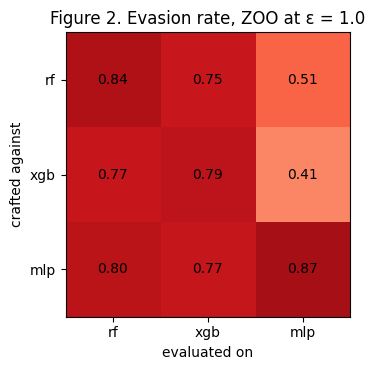

> #### Findings
> | Check | Result |
> |---|---|
> | Mean adaptive (diagonal) evasion | 0.835 |
> | Mean transferred (off-diagonal) evasion | 0.669 |
>
> **Meaning:** if transferred evasion is much lower than adaptive evasion, disagreement *between models* is itself a warning sign, which motivates combining several indicators in Part 4.


In [66]:
TR = RES[(RES.set == "test_lite") & (RES.attack == "zoo") & (RES.eps == emax) & RES.evaluated_on.isin(CLASSIFIERS)]
TRANSFER = TR.pivot_table(index="target", columns="evaluated_on", values="evasion_rate").loc[CLASSIFIERS, CLASSIFIERS]
fig, ax = plt.subplots(figsize=(4.5 + len(CLASSIFIERS), 3.8))
ax.imshow(TRANSFER.to_numpy(), cmap="Reds", vmin=0, vmax=1)
for i in range(len(CLASSIFIERS)):
    for j in range(len(CLASSIFIERS)):
        ax.text(j, i, f"{TRANSFER.iat[i, j]:.2f}", ha="center", va="center")
ax.set_xticks(range(len(CLASSIFIERS))); ax.set_xticklabels(CLASSIFIERS); ax.set_yticks(range(len(CLASSIFIERS))); ax.set_yticklabels(CLASSIFIERS)
ax.set_xlabel("evaluated on"); ax.set_ylabel("crafted against"); ax.set_title(f"Figure 2. Evasion rate, ZOO at ε = {emax}")
savefig("02_transfer.png")
off = TRANSFER.to_numpy()[~np.eye(len(CLASSIFIERS), dtype=bool)]
findings([("Mean adaptive (diagonal) evasion", f"{np.diag(TRANSFER.to_numpy()).mean():.3f}"),
          ("Mean transferred (off-diagonal) evasion", f"{off.mean():.3f}" if off.size else "n/a")],
         "if transferred evasion is much lower than adaptive evasion, disagreement *between models* is itself a warning "
         "sign, which motivates combining several indicators in Part 4.")

## 3.8 · Explanation stability under attack
For every attack flow of `test-lite`, SHAP is recomputed on its adversarial version (explaining the class the model now predicts) and compared with the clean SHAP of the same flow from Part 2:

| Metric | Meaning | Range |
|---|---|---|
| Kendall τ | agreement of the full feature ranking by \|SHAP\| | −1 … 1 |
| top-5 / top-10 Jaccard | overlap of the most important features | 0 … 1 |
| RBO (p = 0.9) | rank-biased overlap (Webber, Moffat and Zobel, 2010): agreement weighted towards the top of the ranking | 0 … 1 |
| group τ | Kendall τ of importance per **feature group** (Part 1) | −1 … 1 |
| cosine | similarity of the signed SHAP vectors | −1 … 1 |
| reachable share | share of the explanation change that falls on attacker-reachable features | 0 … 1 |

Results are split by whether the prediction **flipped**: an explanation that changes because the decision changed is expected; an explanation that changes while the decision stays the same is the worrying case for an analyst who relies on it.

rf: SHAP on attacked flows done (2234 s)
xgb: SHAP on attacked flows done (2267 s)
mlp: SHAP on attacked flows done (4058 s)


kendall_tau  top5_jaccard  top10_jaccard    rbo  group_tau  cosine  reachable_share  flipped_%
model attack eps                                                                                                 
mlp   noise  0.05        0.698         0.619          0.661  0.730      0.772   0.906            0.668        0.3
             0.10        0.696         0.610          0.657  0.726      0.769   0.901            0.672        0.4
             0.20        0.677         0.589          0.630  0.706      0.752   0.843            0.672        5.7
             0.50        0.635         0.521          0.568  0.643      0.712   0.714            0.671       17.3
             1.00        0.590         0.438          0.501  0.564      0.668   0.607            0.681       27.9
      zoo    0.05        0.688         0.613          0.645  0.724      0.757   0.867            0.665        3.8
             0.10        0.648         0.572          0.586  0.681      0.712   0.701            0.659       19.2
             0.20        0.612         0.512          0.533  0.630      0.680   0.573            0.653       30.1
             0.50        0.545         0.377          0.409  0.506      0.615   0.350            0.655       49.9
             1.00        0.472         0.248          0.294  0.389      0.559   0.033            0.658       77.7
rf    noise  0.05        0.795         0.706          0.714  0.772      0.841   0.783            0.752       22.2
             0.10        0.769         0.664          0.680  0.736      0.819   0.734            0.749       27.0
             0.20        0.727         0.587          0.613  0.674      0.782   0.661            0.737       38.3
             0.50        0.674         0.491          0.534  0.608      0.732   0.643            0.723       49.1
             1.00        0.629         0.410          0.474  0.555      0.682   0.576            0.696       60.1
      zoo    0.05        0.784         0.636          0.691  0.744      0.840   0.753            0.743       26.4
             0.10        0.751         0.578          0.631  0.683      0.810   0.694            0.735       34.6
             0.20        0.677         0.471          0.531  0.588      0.736   0.597            0.720       52.1
             0.50        0.618         0.383          0.455  0.536      0.682   0.561            0.691       61.9
             1.00        0.586         0.353          0.410  0.498      0.629   0.523            0.666       71.3
xgb   noise  0.05        0.832         0.657          0.708  0.756      0.859   0.622            0.834       10.4
             0.10        0.810         0.627          0.685  0.726      0.840   0.596            0.833       14.6
             0.20        0.776         0.590          0.646  0.689      0.815   0.566            0.819       20.9
             0.50        0.715         0.514          0.574  0.620      0.772   0.504            0.788       32.5
             1.00        0.647         0.405          0.490  0.530      0.710   0.424            0.760       45.4
      zoo    0.05        0.802         0.642          0.673  0.716      0.827   0.594            0.819       17.8
             0.10        0.756         0.592          0.642  0.664      0.782   0.541            0.815       28.6
             0.20        0.709         0.536          0.584  0.611      0.752   0.492            0.792       38.2
             0.50        0.645         0.416          0.497  0.528      0.719   0.412            0.750       51.0
             1.00        0.549         0.309          0.389  0.425      0.632   0.264            0.713       66.3

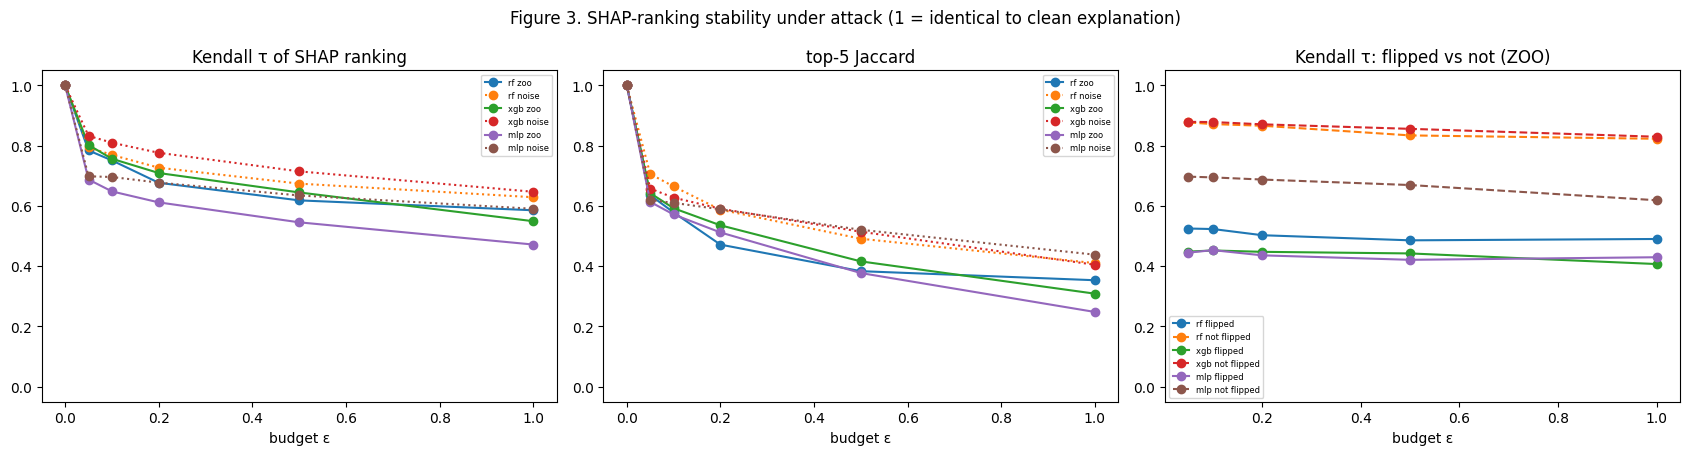

(4059 s)


In [67]:
SH = np.load(NB2 / "shap_clean.npz", allow_pickle=True)
S_POS = pd.Series(np.arange(len(SH["row_id"])), index=SH["row_id"])
bg_rows = SH["background_rows"]
grp_of = {f: g for g, fl in FEATURE_GROUPS.items() for f in fl}
GROUPS = sorted({grp_of.get(c, "missing_indicator" if c.endswith("__missing") else "other") for c in COLS})
G = np.array([[grp_of.get(c, "missing_indicator" if c.endswith("__missing") else "other") == g for c in COLS] for g in GROUPS], dtype=float)
REACH = np.array([SPEC["features"].get(c.replace("__missing", ""), {"role": "n/a"})["role"] in ("controllable", "dependent") for c in COLS])

def shap_pred(m, X):
    if m in ("rf", "xgb"):
        sv = shap.TreeExplainer(MODELS[m]).shap_values(X, check_additivity=False)
    else:
        background = torch.as_tensor(model_input(clean.iloc[bg_rows][FEATS])).to(DEVICE)
        gx = shap.GradientExplainer(MODELS["mlp"].eval(), background, batch_size=500)
        sv = gx.shap_values(torch.as_tensor(X).to(DEVICE), nsamples=50, rseed=SEED)
    a = np.stack(sv, -1) if isinstance(sv, list) else np.asarray(sv)
    if a.shape[0] != len(X): a = np.transpose(a, (1, 2, 0))
    return a[np.arange(len(X)), :, raw_logits(m, X).argmax(1)]

def rbo(a, b, p=RBO_P, depth=RBO_DEPTH):
    A, B, s, ov = set(), set(), 0.0, 0
    for d in range(depth):
        x, y = a[d], b[d]
        ov += (1 if x == y else (x in B) + (y in A)); A.add(x); B.add(y)
        s += p ** d * ov / (d + 1)
    return (1 - p) * s / (1 - p ** depth)

def stability(S0, S1):
    a0, a1 = np.abs(S0), np.abs(S1); o0, o1 = np.argsort(-a0, 1), np.argsort(-a1, 1); out = {}
    out["kendall_tau"] = np.array([kendalltau(x, y).statistic for x, y in zip(a0, a1)])
    for k in TOP_K:
        out[f"top{k}_jaccard"] = np.array([len(set(x[:k]) & set(y[:k])) / len(set(x[:k]) | set(y[:k])) for x, y in zip(o0, o1)])
    out["rbo"] = np.array([rbo(x, y) for x, y in zip(o0, o1)])
    g0, g1 = a0 @ G.T, a1 @ G.T
    out["group_tau"] = np.array([kendalltau(x, y).statistic for x, y in zip(g0, g1)])
    num = (S0 * S1).sum(1); den = np.linalg.norm(S0, axis=1) * np.linalg.norm(S1, axis=1)
    out["cosine"] = np.where(den > 0, num / np.maximum(den, 1e-12), 1.0)
    dlt = np.abs(S1 - S0); tot = dlt.sum(1)
    out["reachable_share"] = np.where(tot > 0, dlt[:, REACH].sum(1) / np.maximum(tot, 1e-12), np.nan)
    return {k: np.nan_to_num(v, nan=1.0) if k != "reachable_share" else v for k, v in out.items()}

t0 = time.time(); STAB, SHAP_ADV, SHAP_TIME = [], {}, {}
for m in CLASSIFIERS:
    for attack in SHAP_ATTACKS:
        for eps in SHAP_EPS:
            key = ("test_lite", attack, m if attack == "zoo" else "none", eps)
            adv = ADV[key]; X1 = model_input(adv); t = time.time()
            S1 = shap_pred(m, X1); SHAP_TIME[m] = (time.time() - t) / len(X1)
            S0 = SH[f"{m}_pred"][S_POS.loc[adv.index].to_numpy()]
            p0 = raw_logits(m, model_input(clean.loc[adv.index, FEATS])).argmax(1); p1 = raw_logits(m, X1).argmax(1)
            st = stability(S0, S1); SHAP_ADV[(m, attack, eps)] = S1.astype("float32")
            STAB.append(pd.DataFrame({"model": m, "attack": attack, "eps": eps, "row_id": adv.index, "flipped": p0 != p1,
                                      "label": clean.loc[adv.index, "label_family"].to_numpy(), **st}))
    print(f"{m}: SHAP on attacked flows done ({time.time() - t0:.0f} s)")
STAB = pd.concat(STAB, ignore_index=True)
METRICS = ["kendall_tau", "top5_jaccard", "top10_jaccard", "rbo", "group_tau", "cosine"]
SUMMARY = STAB.groupby(["model", "attack", "eps"])[METRICS + ["reachable_share"]].mean().round(3)
SUMMARY["flipped_%"] = (100 * STAB.groupby(["model", "attack", "eps"])["flipped"].mean()).round(1)
display(SUMMARY)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
for m in CLASSIFIERS:
    for attack, st in [("zoo", "-"), ("noise", ":")]:
        d = STAB[(STAB.model == m) & (STAB.attack == attack)].groupby("eps")
        axes[0].plot([0] + list(d.groups), [1.0] + d["kendall_tau"].mean().tolist(), st, marker="o", label=f"{m} {attack}")
        axes[1].plot([0] + list(d.groups), [1.0] + d["top5_jaccard"].mean().tolist(), st, marker="o", label=f"{m} {attack}")
    z = STAB[(STAB.model == m) & (STAB.attack == "zoo")]
    for fl, st in [(True, "-"), (False, "--")]:
        d = z[z.flipped == fl].groupby("eps")["kendall_tau"].mean()
        axes[2].plot(d.index, d.values, st, marker="o", label=f"{m} {'flipped' if fl else 'not flipped'}")
for ax, t in zip(axes, ["Kendall τ of SHAP ranking", "top-5 Jaccard", "Kendall τ: flipped vs not (ZOO)"]):
    ax.set_xlabel("budget ε"); ax.set_title(t); ax.legend(fontsize=6); ax.set_ylim(-0.05, 1.05)
plt.suptitle("Figure 3. SHAP-ranking stability under attack (1 = identical to clean explanation)"); savefig("03_shap_stability.png")
print(f"({time.time() - t0:.0f} s)")

### 3.8b · Is the instability caused by the attack, or by any change?
Paired Wilcoxon signed-rank test on the same flows: Kendall τ under ZOO vs under random noise of the same budget. Mann–Whitney U test: Kendall τ of flipped vs unflipped flows. Feature-group stability shows *where* explanations move.

In [68]:
TESTS = []
for m in CLASSIFIERS:
    for eps in SHAP_EPS:
        z = STAB[(STAB.model == m) & (STAB.attack == "zoo") & (STAB.eps == eps)].set_index("row_id")["kendall_tau"]
        n = STAB[(STAB.model == m) & (STAB.attack == "noise") & (STAB.eps == eps)].set_index("row_id")["kendall_tau"].reindex(z.index)
        diff = (z - n).dropna()
        p_less = wilcoxon(diff, alternative="less").pvalue if (diff != 0).any() else 1.0      # ZOO less stable than noise
        p_greater = wilcoxon(diff, alternative="greater").pvalue if (diff != 0).any() else 1.0
        zz = STAB[(STAB.model == m) & (STAB.attack == "zoo") & (STAB.eps == eps)]
        f, nf = zz.loc[zz.flipped, "kendall_tau"], zz.loc[~zz.flipped, "kendall_tau"]
        p_mw = mannwhitneyu(f, nf).pvalue if len(f) > 2 and len(nf) > 2 else np.nan
        TESTS.append({"model": m, "eps": eps, "tau_zoo": round(z.mean(), 3), "tau_noise": round(n.mean(), 3),
                      "p: zoo less stable than noise": p_less, "p: zoo more stable than noise": p_greater, "tau_flipped": round(f.mean(), 3) if len(f) else np.nan,
                      "tau_not_flipped": round(nf.mean(), 3) if len(nf) else np.nan, "mannwhitney_p (flipped vs not)": p_mw})
TESTS = pd.DataFrame(TESTS); display(TESTS)

# Which feature groups gain or lose importance under the strongest attack?
GSHIFT = {}
for m in CLASSIFIERS:
    adv = ADV[("test_lite", "zoo", m, emax)]; S0 = SH[f"{m}_pred"][S_POS.loc[adv.index].to_numpy()]; S1 = SHAP_ADV[(m, "zoo", emax)]
    g0 = (np.abs(S0) @ G.T); g1 = (np.abs(S1) @ G.T)
    GSHIFT[m] = (g1 / g1.sum(1, keepdims=True) - g0 / g0.sum(1, keepdims=True)).mean(0)
GSHIFT = pd.DataFrame(GSHIFT, index=GROUPS).round(3)
display(GSHIFT.sort_values(CLASSIFIERS[0]).rename_axis(f"change in share of |SHAP| at ε = {emax} (ZOO)"))
sig = TESTS[TESTS["p: zoo less stable than noise"] < 0.05]; sig_rev = TESTS[TESTS["p: zoo more stable than noise"] < 0.05]
unfl = (STAB.attack == "zoo") & (STAB.eps == emax) & ~STAB.flipped
UNFLIPPED_CHANGED = 100 * (unfl & (STAB.kendall_tau < 0.8)).sum() / max(unfl.sum(), 1)
findings([(f"{m}: mean Kendall τ at max ε (ZOO / noise)",
           f"{TESTS[(TESTS.model == m) & (TESTS.eps == emax)].tau_zoo.iloc[0]} / {TESTS[(TESTS.model == m) & (TESTS.eps == emax)].tau_noise.iloc[0]}")
          for m in CLASSIFIERS] +
         [("ZOO significantly LESS stable than noise (one-sided p < 0.05)", f"{len(sig)} of {len(TESTS)} model/budget cases"),
          ("ZOO significantly MORE stable than noise", f"{len(sig_rev)} of {len(TESTS)}"),
          ("Unflipped flows whose ranking still changed (τ < 0.8, ZOO, max ε)", f"{UNFLIPPED_CHANGED:.1f}%")],
         ("the targeted attack disturbs explanations more than random change of the same size, so instability is attack-specific. "
          if len(sig) > len(sig_rev) else
          "random change of the same size disturbs explanations at least as much as the targeted attack: explanations are "
          "sensitive to *any* perturbation of the controllable features, not specifically to the attack. The attack achieves "
          "evasion with comparatively small explanation changes, which makes it harder to spot from explanations alone. ")
         + ("Rankings also change on flows whose prediction did not flip, so an analyst could be misled even when the alert is correct."
            if UNFLIPPED_CHANGED >= 5 else "Rankings stay largely intact on flows whose prediction did not flip."))

,model,eps,tau_zoo,tau_noise,p: zoo less stable than noise,p: zoo more stable than noise,tau_flipped,tau_not_flipped,mannwhitney_p (flipped vs not)
0,rf,0.05,0.784,0.795,1.036952e-27,1.0,0.525,0.877,2.405281e-228
1,rf,0.10,0.751,0.769,3.495509e-28,1.0,0.523,0.872,2.035208e-265
2,rf,0.20,0.677,0.727,1.330217e-47,1.0,0.503,0.866,1.026941e-291
3,rf,0.50,0.618,0.674,6.572195e-60,1.0,0.486,0.834,6.300923e-276
4,rf,1.00,0.586,0.629,2.136338e-46,1.0,0.490,0.823,5.083582e-239
5,xgb,0.05,0.802,0.832,1.858724e-21,1.0,0.448,0.879,2.174128e-172
6,xgb,0.10,0.756,0.810,1.262241e-43,1.0,0.452,0.878,2.038722e-239
7,xgb,0.20,0.709,0.776,1.731953e-70,1.0,0.448,0.871,2.052959e-276
8,xgb,0.50,0.645,0.715,2.211483e-53,1.0,0.442,0.856,1.757984e-292
9,xgb,1.00,0.549,0.647,3.120786e-67,1.0,0.407,0.830,2.820345e-261


,rf,xgb,mlp
change in share of |SHAP| at ε = 1.0 (ZOO),,,
header,-0.037,-0.053,-0.026
count_bwd,-0.026,-0.015,0.000
engineered,-0.022,0.008,-0.021
timing_fwd,-0.014,-0.045,0.021
tcp_flags,-0.002,-0.016,0.010
missing_indicator,0.000,-0.000,-0.000
activity,0.001,0.006,0.020
ratio,0.002,-0.001,-0.010
timing_flow,0.002,-0.027,0.001


> #### Findings
> | Check | Result |
> |---|---|
> | rf: mean Kendall τ at max ε (ZOO / noise) | 0.586 / 0.629 |
> | xgb: mean Kendall τ at max ε (ZOO / noise) | 0.549 / 0.647 |
> | mlp: mean Kendall τ at max ε (ZOO / noise) | 0.472 / 0.59 |
> | ZOO significantly LESS stable than noise (one-sided p < 0.05) | 15 of 15 model/budget cases |
> | ZOO significantly MORE stable than noise | 0 of 15 |
> | Unflipped flows whose ranking still changed (τ < 0.8, ZOO, max ε) | 48.1% |
>
> **Meaning:** the targeted attack disturbs explanations more than random change of the same size, so instability is attack-specific. Rankings also change on flows whose prediction did not flip, so an analyst could be misled even when the alert is correct.


## 3.9 · Answer to RQ1

In [69]:
ANS = []
for m in CLASSIFIERS:
    row = {"model": m, "clean macro-F1": round(DECLINE.loc[m, "clean"], 4)}
    for eps in EPSILONS:
        row[f"F1 ε={eps}"] = round(DECLINE.loc[m, eps], 4)
    row[f"evasion ε={emax}"] = round(float(own[(own.evaluated_on == m) & (own.eps == emax)].evasion_rate.iloc[0]), 3)
    s = SUMMARY.loc[(m, "zoo", emax)]
    row[f"SHAP τ ε={emax}"] = s["kendall_tau"]; row[f"top-5 Jaccard ε={emax}"] = s["top5_jaccard"]; row[f"group τ ε={emax}"] = s["group_tau"]
    ANS.append(row)
ANS = pd.DataFrame(ANS).set_index("model"); display(ANS)
ANS.to_csv(OUT_DIR / "rq1_answer_table.csv")
mono = all(np.all(np.diff(DECLINE.loc[m, EPSILONS].to_numpy()) <= 0.02) for m in CLASSIFIERS)
display(Markdown(
f"""> #### RQ1 · Answer (generated from this run)
> **Detection performance.** Under the adaptive ZOO attack within the threat model, macro-F1 falls from
> {", ".join(f"{DECLINE.loc[m, 'clean']:.3f} to {DECLINE.loc[m, emax]:.3f} ({m})" for m in CLASSIFIERS)} at ε = {emax};
> the decline {"grows steadily" if mono else "is not monotonic"} with the budget. The most robust model is **{most_robust}**, the least robust **{least_robust}**.
> Random noise of the same budget lowers macro-F1 by {", ".join(f"{NOISE_DROP.loc[m, emax]:.3f} ({m})" for m in CLASSIFIERS)}, compared with
> {", ".join(f"{DROP.loc[m, emax]:.3f} ({m})" for m in CLASSIFIERS)} under the targeted attack{", so most of the decline is attack-specific" if (DROP[emax] > 2 * NOISE_DROP[emax]).all() else ""}.
>
> **Explanation stability.** At ε = {emax}, the mean Kendall τ between clean and attacked SHAP rankings is
> {", ".join(f"{SUMMARY.loc[(m, 'zoo', emax), 'kendall_tau']:.2f} ({m})" for m in CLASSIFIERS)}
> (1 = unchanged), against {", ".join(f"{SUMMARY.loc[(m, 'noise', emax), 'kendall_tau']:.2f} ({m})" for m in CLASSIFIERS)} under random noise.
> The attack is significantly less stable than noise in {len(sig)} and significantly more stable in {len(sig_rev)} of {len(TESTS)} model/budget cases.
> Among flows whose prediction did **not** flip, {UNFLIPPED_CHANGED:.1f}% still had their ranking changed substantially (τ < 0.8).
>
> **Implication for RQ2.** Classifier output alone degrades under attack, and its explanation degrades with it. Confidence,
> anomaly evidence and explanation stability are therefore candidate warning indicators; Part 4 tests whether combining them identifies the affected flows.
"""))

,clean macro-F1,F1 ε=0.05,F1 ε=0.1,F1 ε=0.2,F1 ε=0.5,F1 ε=1.0,evasion ε=1.0,SHAP τ ε=1.0,top-5 Jaccard ε=1.0,group τ ε=1.0
model,,,,,,,,,,
rf,0.9223,0.4431,0.4287,0.4185,0.2542,0.2066,0.839,0.586,0.353,0.629
xgb,0.9501,0.6555,0.5363,0.5248,0.3537,0.2532,0.794,0.549,0.309,0.632
mlp,0.9184,0.7252,0.6743,0.6419,0.4136,0.1936,0.870,0.472,0.248,0.559


> #### RQ1 · Answer (generated from this run)
> **Detection performance.** Under the adaptive ZOO attack within the threat model, macro-F1 falls from
> 0.922 to 0.207 (rf), 0.950 to 0.253 (xgb), 0.918 to 0.194 (mlp) at ε = 1.0;
> the decline grows steadily with the budget. The most robust model is **xgb**, the least robust **mlp**.
> Random noise of the same budget lowers macro-F1 by 0.594 (rf), 0.529 (xgb), 0.294 (mlp), compared with
> 0.716 (rf), 0.697 (xgb), 0.725 (mlp) under the targeted attack.
>
> **Explanation stability.** At ε = 1.0, the mean Kendall τ between clean and attacked SHAP rankings is
> 0.59 (rf), 0.55 (xgb), 0.47 (mlp)
> (1 = unchanged), against 0.63 (rf), 0.65 (xgb), 0.59 (mlp) under random noise.
> The attack is significantly less stable than noise in 15 and significantly more stable in 0 of 15 model/budget cases.
> Among flows whose prediction did **not** flip, 48.1% still had their ranking changed substantially (τ < 0.8).
>
> **Implication for RQ2.** Classifier output alone degrades under attack, and its explanation degrades with it. Confidence,
> anomaly evidence and explanation stability are therefore candidate warning indicators; Part 4 tests whether combining them identifies the affected flows.


## 3.9b · Sensitivity check: how much of the vulnerability comes from the TCP window?
Under the strongest ZOO attack, the share of SHAP importance carried by the `tcp_window` group rises more than any other group (Section 3.8b), and `Init_Win_bytes_forward` is the one controllable feature the attacker may move in **both** directions. The adaptive ZOO attack is therefore repeated at the smallest and the largest budget with that feature frozen: if macro-F1 then falls much less, most of the vulnerability rests on one feature, which is a concrete, actionable finding (e.g. for feature hardening). The second part relates the random-noise control to the targeted attack: the share of the targeted macro-F1 drop that random change of the same size already causes.

In [70]:
ABL_FEATURE = "Init_Win_bytes_forward"
ABL_EPS = sorted({min(EPSILONS), emax})
j_abl = CTRL.index(ABL_FEATURE)
_bounds_full = bounds
def bounds(eps):                                   # same attack, but the ablated feature may not move
    lo, hi = _bounds_full(eps); lo, hi = lo.copy(), hi.copy(); lo[j_abl] = hi[j_abl] = 0.0
    return lo, hi

t0, WIN_ABL = time.time(), []
try:
    rows_tl = SETS["test_lite"]; y_tl = clean["label_id"].to_numpy()[rows_tl]; att_tl = y_tl != BENIGN_ID
    att_rows = rows_tl[att_tl]
    base = clean.iloc[att_rows][FEATS].reset_index(drop=True); scale = scale_of(base)
    for eps in ABL_EPS:
        for m in CLASSIFIERS:
            r = np.random.default_rng(SEED + int(eps * 1000))
            adv = realise(base, attack_zoo(base, scale, eps, r, m), scale); adv.index = att_rows
            assert np.allclose(adv[ABL_FEATURE].to_numpy("float64"), base[ABL_FEATURE].to_numpy("float64"), equal_nan=True)
            _, Xa = set_inputs("test_lite", adv); p = proba(m, Xa).argmax(1)
            full = own[(own.evaluated_on == m) & (own.eps == eps)].iloc[0]
            WIN_ABL.append({"model": m, "eps": eps, "clean macro-F1": DECLINE.loc[m, "clean"],
                            "macro-F1, full threat model": full.macro_F1, f"macro-F1, {ABL_FEATURE} frozen": macro_f1(y_tl, p),
                            "evasion, full threat model": full.evasion_rate, f"evasion, {ABL_FEATURE} frozen": float((p[att_tl] == BENIGN_ID).mean())})
finally:
    bounds = _bounds_full                           # restore the full threat model
WIN_ABL = pd.DataFrame(WIN_ABL)
WIN_ABL["share of the F1 drop removed by freezing"] = ((WIN_ABL[f"macro-F1, {ABL_FEATURE} frozen"] - WIN_ABL["macro-F1, full threat model"])
                                                        / (WIN_ABL["clean macro-F1"] - WIN_ABL["macro-F1, full threat model"]).clip(lower=1e-9))
display(WIN_ABL.round(4)); WIN_ABL.to_csv(OUT_DIR / "window_feature_ablation.csv", index=False)
NOISE_SHARE = (NOISE_DROP[emax] / DROP[emax]).clip(upper=9.99)
removed = WIN_ABL[WIN_ABL.eps == emax].set_index("model")["share of the F1 drop removed by freezing"]
print(f"({time.time() - t0:.0f} s)")
findings([(f"{m}: share of the ZOO drop at ε = {emax} removed by freezing {ABL_FEATURE}", f"{removed[m]:.0%}") for m in CLASSIFIERS] +
         [(f"{m}: random-noise drop as a share of the ZOO drop at ε = {emax}", f"{NOISE_SHARE[m]:.0%}") for m in CLASSIFIERS],
         (f"freezing one feature removes much of the attack's effect, so the models' vulnerability is concentrated in the TCP window. "
          if removed.mean() >= 0.5 else
          f"freezing {ABL_FEATURE} removes only part of the attack's effect, so the vulnerability is spread over several controllable features. ")
         + ("Random change of the same size already causes most of the drop, so the models are fragile to any realistic change of the "
            "client-side features; the targeted attack adds a further, significant drop on top."
            if NOISE_SHARE.mean() >= 0.5 else
            "Random change of the same size causes a much smaller drop, so most of the decline is attack-specific."))

,model,eps,clean macro-F1,"macro-F1, full threat model","macro-F1, Init_Win_bytes_forward frozen","evasion, full threat model","evasion, Init_Win_bytes_forward frozen",share of the F1 drop removed by freezing
0,rf,0.05,0.9223,0.4431,0.4912,0.5794,0.5070,0.1004
1,xgb,0.05,0.9501,0.6555,0.7699,0.4105,0.2569,0.3884
2,mlp,0.05,0.9184,0.7252,0.7285,0.3017,0.2956,0.0173
3,rf,1.00,0.9223,0.2066,0.2127,0.8390,0.8301,0.0086
4,xgb,1.00,0.9501,0.2532,0.4093,0.7942,0.6354,0.2241
5,mlp,1.00,0.9184,0.1936,0.2476,0.8704,0.8205,0.0746


(48 s)


> #### Findings
> | Check | Result |
> |---|---|
> | rf: share of the ZOO drop at ε = 1.0 removed by freezing Init_Win_bytes_forward | 1% |
> | xgb: share of the ZOO drop at ε = 1.0 removed by freezing Init_Win_bytes_forward | 22% |
> | mlp: share of the ZOO drop at ε = 1.0 removed by freezing Init_Win_bytes_forward | 7% |
> | rf: random-noise drop as a share of the ZOO drop at ε = 1.0 | 83% |
> | xgb: random-noise drop as a share of the ZOO drop at ε = 1.0 | 76% |
> | mlp: random-noise drop as a share of the ZOO drop at ε = 1.0 | 41% |
>
> **Meaning:** freezing Init_Win_bytes_forward removes only part of the attack's effect, so the vulnerability is spread over several controllable features. Random change of the same size already causes most of the drop, so the models are fragile to any realistic change of the client-side features; the targeted attack adds a further, significant drop on top.


## 3.10 · Final checks

In [71]:
cl = RES[(RES.set == "test_lite") & (RES.attack == "clean") & RES.evaluated_on.isin(CLASSIFIERS)].set_index("evaluated_on")["macro_F1"]
nb2_clean = pd.read_csv(NB2 / "clean_eval.csv"); nb2_clean = nb2_clean[nb2_clean.split == "test_lite"].set_index("model")["macro_F1"]
checks = {
    "transformation reproduces Part 1 inputs": bool(consistent),
    "clean test-lite macro-F1 matches Part 2": bool(np.allclose(cl.loc[CLASSIFIERS], nb2_clean.loc[CLASSIFIERS], atol=1e-3)),
    "zero hard threat-model violations": bool(hard.sum() == 0),
    "benign flows never perturbed": all((clean["label_id"].to_numpy()[adv.index] != BENIGN_ID).all() for adv in ADV.values()),
    "every configuration evaluated on every model": len(RES[RES.evaluated_on.isin(CLASSIFIERS)]) == len(configs) * len(CLASSIFIERS),
    "SHAP stability computed for every attack flow": all(len(SHAP_ADV[k]) == len(ADV[("test_lite", k[1], k[0] if k[1] == "zoo" else "none", k[2])]) for k in SHAP_ADV),
}
display(pd.DataFrame([(k, "✔ pass" if v else "✘ FAIL") for k, v in checks.items()], columns=["check", "result"]))
assert all(checks.values()), "A final check failed."

,check,result
0,transformation reproduces Part 1 inputs,✔ pass
1,clean test-lite macro-F1 matches Part 2,✔ pass
2,zero hard threat-model violations,✔ pass
3,benign flows never perturbed,✔ pass
4,every configuration evaluated on every model,✔ pass
5,SHAP stability computed for every attack flow,✔ pass


## 3.11 · Saved outputs

In [72]:
adv_frames = []
for (s, attack, tgt, eps), adv in ADV.items():
    d = adv[PARAMS["model_features"]].astype("float32").copy()
    d.insert(0, "row_id", adv.index); d.insert(0, "eps", eps); d.insert(0, "target", tgt); d.insert(0, "attack", attack); d.insert(0, "set", s)
    adv_frames.append(d)
pd.concat(adv_frames, ignore_index=True).to_parquet(OUT_DIR / "adversarial_flows.parquet", compression="zstd", index=False)

pr = []
for rec in PRED_STORE:
    d = pd.DataFrame({"set": rec["set"], "attack": rec["attack"], "target": rec["target"], "eps": rec["eps"],
                      "row_id": rec["row_id"], "label_id": rec["label_id"]})
    for m in CLASSIFIERS:
        for k, c in enumerate(CLASSES): d[f"{m}_p_{c}"] = rec[f"{m}_P"][:, k]
    for a in DETECTORS: d[f"{a}_pvalue"] = rec[f"{a}_pvalue"]
    pr.append(d)
pd.concat(pr, ignore_index=True).to_parquet(OUT_DIR / "attack_predictions.parquet", compression="zstd", index=False)
STAB.to_parquet(OUT_DIR / "shap_stability_per_flow.parquet", index=False)
np.savez_compressed(OUT_DIR / "shap_adversarial.npz", **{f"{m}|{a}|{e}": v for (m, a, e), v in SHAP_ADV.items()},
                    **{f"rows|{m}|{a}|{e}": ADV[("test_lite", a, m if a == "zoo" else "none", e)].index.to_numpy() for (m, a, e) in SHAP_ADV})
RES.to_csv(OUT_DIR / "detection_under_attack.csv", index=False); DECLINE.to_csv(OUT_DIR / "macro_f1_decline.csv")
FAM_EVASION.to_csv(OUT_DIR / "evasion_by_family.csv"); TRANSFER.to_csv(OUT_DIR / "transfer_matrix.csv")
SUMMARY.to_csv(OUT_DIR / "shap_stability_summary.csv"); TESTS.to_csv(OUT_DIR / "shap_stability_tests.csv", index=False)
GSHIFT.to_csv(OUT_DIR / "shap_group_shift.csv"); COMP.to_csv(OUT_DIR / "threat_model_compliance.csv", index=False)
COST = TIMES.groupby(["attack", "target"])[["ms_per_flow", "queries_per_flow"]].mean().round(2)
for m in CLASSIFIERS: COST.loc[("shap_on_attacked_flows", m), "ms_per_flow"] = round(1e3 * SHAP_TIME[m], 2)
COST.to_csv(OUT_DIR / "attack_cost.csv")
json.dump({"epsilons": EPSILONS, "attacks": ATTACKS, "target_class": TARGET_CLASS, "zoo_steps": ZOO_STEPS,
           "zoo_h_frac": ZOO_H_FRAC, "zoo_lr_frac": ZOO_LR_FRAC, "shap_eps": SHAP_EPS, "controllable": CTRL,
           "typical_scale": dict(zip(CTRL, TYPICAL)), "nb1_dir": str(NB1), "nb2_dir": str(NB2), "notebook_id": NOTEBOOK_ID},
          open(OUT_DIR / "attack_config.json", "w"), indent=2, default=to_builtin)
display(pd.DataFrame([(str(p.relative_to(OUT_DIR)), round(p.stat().st_size / 1e6, 2)) for p in sorted(OUT_DIR.rglob("*"))
                      if p.is_file()], columns=["file", "size_mb"]))

,file,size_mb
0,adversarial_flows.parquet,4.40
1,attack_config.json,0.00
2,attack_cost.csv,0.00
3,attack_predictions.parquet,9.59
4,detection_under_attack.csv,0.03
5,evasion_by_family.csv,0.00
6,figures/01_detection_under_attack.png,0.38
7,figures/02_transfer.png,0.04
8,figures/03_shap_stability.png,0.25
9,macro_f1_decline.csv,0.00


> #### Saved files
> | File | Use |
> |---|---|
> | `adversarial_flows.parquet` | every adversarial flow (real units) for `test-lite` and `thr-lite`, per attack, target model and ε: input to Parts 4 and 5 |
> | `attack_predictions.parquet` | calibrated probabilities of every classifier and anomaly p-values for clean and attacked versions of every set |
> | `shap_stability_per_flow.parquet`, `shap_adversarial.npz` | RQ1 explanation-stability evidence; SHAP of attacked flows |
> | `rq1_answer_table.csv`, `macro_f1_decline.csv`, `transfer_matrix.csv`, `shap_stability_*.csv` | tables for the report |
> | `attack_cost.csv` | attack and explanation cost per flow (RQ4) |
> | `window_feature_ablation.csv` | sensitivity of the attack to the TCP-window feature, and noise-vs-attack share (Section 3.9b) |

## 3.12 · Contribution to the research questions
| RQ | Contribution |
|---|---|
| **RQ1** | **answered here** (Section 3.9): macro-F1 decline per model and budget, evasion and transfer, SHAP-ranking stability at feature and group level, with controls and significance tests |
| **RQ2** | attacked `thr-lite` / `test-lite` flows with all model outputs: the cases in which classifier, anomaly detector and explanation are expected to disagree |
| **RQ3** | perturbed data on which the mechanism, the individual models and the multi-agent systems are compared (O3: "macro-F1 for perturbed data") |
| **RQ4** | attack generation and explanation cost per flow |

#### Next: Part 4 · Confidence-aware decision mechanism (RQ2)
Compute the three trust indicators for every clean and attacked flow (calibrated confidence, anomaly p-value, SHAP stability without access to the clean version), detect disagreement, tune the accept / flag / escalate rules on `thr-lite` and evaluate on `test-lite`.

> #### ✅ Part 3 · Key takeaways (reported run)
> - Under the adaptive ZOO attack macro-F1 collapses from **0.92–0.95 to 0.19–0.25** at ε = 1.0; even ε = 0.05 costs up to 0.48 points. Evasion reaches 79–87 %.
> - Attacks crafted on one model transfer to others (mean evasion 0.669 vs 0.835 adaptive), so *disagreement between indicators* is informative.
> - SHAP rankings change markedly (Kendall τ 0.47–0.59 vs 0.59–0.65 under random noise; ZOO is significantly less stable in **15 of 15** cases), and **48.1 %** of flows whose prediction did *not* flip still had their explanation substantially changed.
> - Random noise already causes 41–83 % of the drop, and freezing the TCP-window feature removes only 1–22 %: the models are broadly fragile, not dependent on one shortcut.

↑ back to contents (Notebook 1)

---
## Viva guide for this notebook

**Suggested demonstration path (about 5 minutes)**
1. **Figure 3.1**: the attack engine (every candidate passes the threat model).
2. **3.5**: compliance check, 0 violations.
3. **3.6**: macro-F1 under attack (Figure: detection collapses).
4. **3.8 / 3.8b**: explanation stability and the Wilcoxon tests (15 of 15).
5. **3.9**: the answer to RQ1.

**Likely questions and short answers**

| Question | Answer |
|---|---|
| Why ZOO and not FGSM or PGD? | Those need gradients; tree models have none. ZOO needs only queries, and its estimated steps pass through the projection, so every step stays realistic. |
| Are your adversarial flows realistic? | Yes: only the 13 client-side features move, only in allowed directions, integers stay integers, values stay below the 99.9 % training quantile; 0 violations. |
| Why compare with random noise? | To show the explanation change is caused by the targeted attack, not by any change: ZOO was significantly less stable in all 15 cases. |
| Why does the MLP collapse most at ε = 1.0? | Its smooth decision function can be pushed steadily towards Benign once the budget is large; trees are more fragile to small changes. |
| Why does explanation stability matter? | 48.1 % of correctly classified attacked flows had a changed explanation, so an analyst could be misled even when the alert is right. |
| Is the vulnerability one feature? | No. Freezing the TCP-window feature removed only part of the drop, so the fragility is spread across features. |